In [36]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import AdaBoostClassifier

In [7]:
df=pd.read_csv("insurance.csv")
df=df.drop('charges',axis=1)
df.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [8]:
df.smoker.value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [9]:
df1=df.copy()
df2=df.copy()
df3=df.copy()
df4=df.copy()
df5=df.copy()
df6=df.copy()
df7=df.copy()
df8=df.copy()
df9=df.copy()

In [10]:
# LABEL ENCODING
from sklearn.preprocessing import LabelEncoder

le=LabelEncoder()
cols = ['sex', 'smoker','region']
for col in cols:
  df1[col]=le.fit_transform(df1[col])

df1.head()


,age,sex,bmi,children,smoker,region
0,19,0,27.900,0,1,3
1,18,1,33.770,1,0,2
2,28,1,33.000,3,0,2
3,33,1,22.705,0,0,1
4,32,1,28.880,0,0,1


In [11]:
#LABEL ENCODING USING LOOP ON ENTIRE DATASET

from pandas.core.dtypes.common import is_numeric_dtype


In [12]:
df2.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [13]:
for col in df2.columns:
    if is_numeric_dtype(df2[col]):
        continue
    else:
        df2[col]=le.fit_transform(df2[col])

df2.head() 

,age,sex,bmi,children,smoker,region
0,19,0,27.900,0,1,3
1,18,1,33.770,1,0,2
2,28,1,33.000,3,0,2
3,33,1,22.705,0,0,1
4,32,1,28.880,0,0,1


In [14]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
dtype: int64

In [15]:
#Perform Label  Encoding using loop
for col in df3.columns:
    if df3[col].dtype == np.number:
        continue
    else:
        df3[col]=le.fit_transform(df3[col])

In [16]:
df3.head()

,age,sex,bmi,children,smoker,region
0,1,0,197,0,1,3
1,0,1,350,1,0,2
2,10,1,331,3,0,2
3,15,1,73,0,0,1
4,14,1,223,0,0,1


In [17]:
X=df3.drop(['smoker'],axis=1)
X.head()
X.shape

(1338, 5)

In [18]:
Y=df3[['smoker']]
Y.shape

(1338, 1)

In [19]:
xtrain,xtest,ytrain,ytest=train_test_split(X,Y,random_state=42,test_size=0.30)

In [20]:
lr=LogisticRegression()

In [21]:
lr.fit(xtrain,ytrain)

C:\Users\dipto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [22]:
predicted_value=lr.predict(xtest)
print("LR Accuracy:",lr.score(xtest,ytest))
print(classification_report(ytest,lr.predict(xtest)))

LR Accuracy: 0.8034825870646766
              precision    recall  f1-score   support

           0       0.80      1.00      0.89       323
           1       0.00      0.00      0.00        79

    accuracy                           0.80       402
   macro avg       0.40      0.50      0.45       402
weighted avg       0.65      0.80      0.72       402



C:\Users\dipto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\dipto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\dipto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [23]:
smot=SMOTE()
X1,Y1=smot.fit_resample(X,Y)

In [24]:
Y1.value_counts()

smoker
0         1064
1         1064
Name: count, dtype: int64

In [25]:
xtrain1,xtest1,ytrain1,ytest1=train_test_split(X1,Y1,random_state=42,test_size=0.30)

In [26]:
lr1=LogisticRegression()

In [27]:
lr1.fit(xtrain1,ytrain1)

C:\Users\dipto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [28]:
predicted_value=lr1.predict(xtest1)
print("LR Accuracy:",lr1.score(xtest1,ytest1))
print(classification_report(ytest1,lr1.predict(xtest1)))

LR Accuracy: 0.5884194053208138
              precision    recall  f1-score   support

           0       0.59      0.56      0.58       319
           1       0.58      0.62      0.60       320

    accuracy                           0.59       639
   macro avg       0.59      0.59      0.59       639
weighted avg       0.59      0.59      0.59       639



In [29]:
model=AdaBoostClassifier()

In [30]:
model.fit(xtrain,ytrain)

C:\Users\dipto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None


In [35]:
predicted_value=model.predict(xtest1)
print("LR Accuracy:",model.score(xtest1,ytest1))
print(classification_report(ytest1,model.predict(xtest1)))

LR Accuracy: 0.6259780907668232
              precision    recall  f1-score   support

           0       0.69      0.46      0.55       319
           1       0.59      0.79      0.68       320

    accuracy                           0.63       639
   macro avg       0.64      0.63      0.61       639
weighted avg       0.64      0.63      0.62       639



<Axes: >

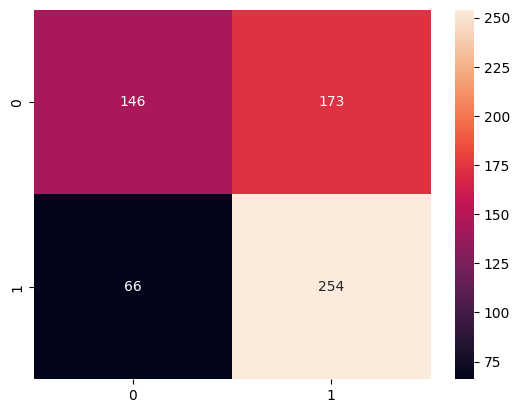

In [37]:
sns.heatmap(confusion_matrix(ytest1, predicted_value), annot=True,fmt='d')

In [8]:
#ONE HOT ENCODING USING 
df3.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [9]:
#SINGLE COLUMN
dummy=pd.get_dummies(df3['sex'],dtype=int)
dummy.head()

,female,male
0,1,0
1,0,1
2,0,1
3,0,1
4,0,1


In [10]:
df3=df3.drop('sex',axis=1)
df3.head()

,age,bmi,children,smoker,region
0,19,27.900,0,yes,southwest
1,18,33.770,1,no,southeast
2,28,33.000,3,no,southeast
3,33,22.705,0,no,northwest
4,32,28.880,0,no,northwest


In [11]:
df3=pd.concat([df3,dummy],axis=1)
df3.head()

,age,bmi,children,smoker,region,female,male
0,19,27.900,0,yes,southwest,1,0
1,18,33.770,1,no,southeast,0,1
2,28,33.000,3,no,southeast,0,1
3,33,22.705,0,no,northwest,0,1
4,32,28.880,0,no,northwest,0,1


In [12]:
df4.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [13]:
#Multiple Column ata a same time
#df4.head()
dummy=pd.get_dummies(df4[['sex','smoker','region']],dtype=int)
dummy.head()
df4=pd.concat([df4,dummy],axis=1)
df4.head()

,age,sex,bmi,children,smoker,region,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,female,27.900,0,yes,southwest,1,0,0,1,0,0,0,1
1,18,male,33.770,1,no,southeast,0,1,1,0,0,0,1,0
2,28,male,33.000,3,no,southeast,0,1,1,0,0,0,1,0
3,33,male,22.705,0,no,northwest,0,1,1,0,0,1,0,0
4,32,male,28.880,0,no,northwest,0,1,1,0,0,1,0,0


In [14]:
#ONE HOT ENCODING USING LOOP
#df5.head()
for col in df5.columns:
    if is_numeric_dtype(df5[col]):
        continue
    else:
        one = pd.get_dummies(df5[col],dtype=int)
        df5=df5.drop(df5[[col]],axis=1)
        df5=pd.concat([df5,one],axis=1)

df5.head()        


,age,bmi,children,female,male,no,yes,northeast,northwest,southeast,southwest
0,19,27.900,0,1,0,0,1,0,0,0,1
1,18,33.770,1,0,1,1,0,0,0,1,0
2,28,33.000,3,0,1,1,0,0,0,1,0
3,33,22.705,0,0,1,1,0,0,1,0,0
4,32,28.880,0,0,1,1,0,0,1,0,0


In [15]:
#ORDINAL ENCODING
df6.head()
from sklearn.preprocessing import OrdinalEncoder
df6.head()


,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [16]:
sex=df6['sex'].unique()
sex

array(['female', 'male'], dtype=object)

In [17]:
ordinal=OrdinalEncoder(categories=[sex])
ordinal

,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute.",[array(['femal... dtype=object)]
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'use_encoded_value'}, default='error'When set to 'error' an error will be raised in case an unknowncategorical feature is present during transform. When set to'use_encoded_value', the encoded value of unknown categories will beset to the value given for the parameter `unknown_value`. In:meth:`inverse_transform`, an unknown category will be denoted as None... versionadded:: 0.24",'error'
,"unknown_value unknown_value: int or np.nan, default=NoneWhen the parameter handle_unknown is set to 'use_encoded_value', thisparameter is required and will set the encoded value of unknowncategories. It has to be distinct from the values used to encode any ofthe categories in `fit`. If set to np.nan, the `dtype` parameter mustbe a float dtype... versionadded:: 0.24",None
,"encoded_missing_value encoded_missing_value: int or np.nan, default=np.nanEncoded value of missing categories. If set to `np.nan`, then the `dtype`parameter must be a float dtype... versionadded:: 1.1",nan
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.3 Read more in the :ref:`User Guide `.",None
,"max_categories max_categories: int, default=NoneSpecifies an upper limit to the number of output categories for each inputfeature when considering infrequent categories. If there are infrequentcategories, `max_categories` includes the category representing theinfrequent categories along with the frequent categories. If `None`,there is no limit to the number of output features.`max_categories` do **not** take into account missing or unknowncategories. Setting `unknown_value` or `encoded_missing_value` to aninteger will increase the number of unique integer codes by one each.This can result in up to `max_categories + 2` integer codes... versionadded:: 1.3 Read more in the :ref:`User Guide `.",None


In [18]:
encoded=ordinal.fit_transform(df6[['sex']])
encoded

array([[0.],
       [1.],
       [1.],
       ...,
       [0.],
       [0.],
       [0.]], shape=(1338, 1))

In [19]:
df6['sex']=pd.DataFrame(encoded,columns=['sex'])
df6.head()

,age,sex,bmi,children,smoker,region
0,19,0.0,27.900,0,yes,southwest
1,18,1.0,33.770,1,no,southeast
2,28,1.0,33.000,3,no,southeast
3,33,1.0,22.705,0,no,northwest
4,32,1.0,28.880,0,no,northwest


In [20]:
#MULTIPEL COLUMN PERORMING ORDINAL ENCODING
cols=['sex','smoker','region']
unique_value={col:df6[col].unique() for col in cols}
unique_value

{'sex': array([0., 1.]),
 'smoker': array(['yes', 'no'], dtype=object),
 'region': array(['southwest', 'southeast', 'northwest', 'northeast'], dtype=object)}

In [21]:
ordinal=OrdinalEncoder(categories=[unique_value[col] for col in cols])
ordinal

,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute.","[array([0., 1.]), array(['yes',... dtype=object), ...]"
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'use_encoded_value'}, default='error'When set to 'error' an error will be raised in case an unknowncategorical feature is present during transform. When set to'use_encoded_value', the encoded value of unknown categories will beset to the value given for the parameter `unknown_value`. In:meth:`inverse_transform`, an unknown category will be denoted as None... versionadded:: 0.24",'error'
,"unknown_value unknown_value: int or np.nan, default=NoneWhen the parameter handle_unknown is set to 'use_encoded_value', thisparameter is required and will set the encoded value of unknowncategories. It has to be distinct from the values used to encode any ofthe categories in `fit`. If set to np.nan, the `dtype` parameter mustbe a float dtype... versionadded:: 0.24",None
,"encoded_missing_value encoded_missing_value: int or np.nan, default=np.nanEncoded value of missing categories. If set to `np.nan`, then the `dtype`parameter must be a float dtype... versionadded:: 1.1",nan
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.3 Read more in the :ref:`User Guide `.",None
,"max_categories max_categories: int, default=NoneSpecifies an upper limit to the number of output categories for each inputfeature when considering infrequent categories. If there are infrequentcategories, `max_categories` includes the category representing theinfrequent categories along with the frequent categories. If `None`,there is no limit to the number of output features.`max_categories` do **not** take into account missing or unknowncategories. Setting `unknown_value` or `encoded_missing_value` to aninteger will increase the number of unique integer codes by one each.This can result in up to `max_categories + 2` integer codes... versionadded:: 1.3 Read more in the :ref:`User Guide `.",None


In [22]:
df6[cols]=ordinal.fit_transform(df6[cols])
df6.head()

,age,sex,bmi,children,smoker,region
0,19,0.0,27.900,0,0.0,0.0
1,18,1.0,33.770,1,1.0,1.0
2,28,1.0,33.000,3,1.0,1.0
3,33,1.0,22.705,0,1.0,2.0
4,32,1.0,28.880,0,1.0,2.0


In [23]:
#ORDINAL ENCODING USING LOOP IN A PARTICULAR DATASET
df7.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [27]:
from sklearn.preprocessing import OrdinalEncoder
for col in df7.columns:
    if is_numeric_dtype(df7[col]):
        continue
    else:
        values=df7[col].unique()
        ordinal=OrdinalEncoder(categories=[values])
        encoded=ordinal.fit_transform(df7[[col]])
        df7[col]=pd.DataFrame(encoded,columns=[col])

df7.head()


,age,sex,bmi,children,smoker,region
0,19,0.0,27.900,0,0.0,0.0
1,18,1.0,33.770,1,1.0,1.0
2,28,1.0,33.000,3,1.0,1.0
3,33,1.0,22.705,0,1.0,2.0
4,32,1.0,28.880,0,1.0,2.0
